Data successfully exported to 'spiral_data.npz'


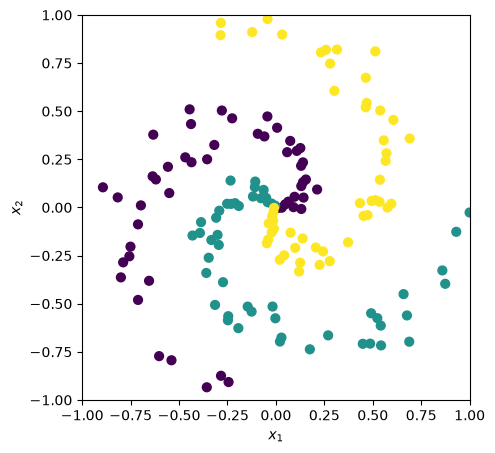

In [3]:
#################################################
#Edit to try different scenarios
#################################################
N = 50 # number of points per branch
K = 3  # number of branches
mag_noise = 0.3  # controls how much noise gets added to the data
dTheta    = 4    # difference in theta in each branch
#################################################

import matplotlib.pyplot as plt
import numpy as np

N_train = N*K # total number of points in the training set
x_train = np.zeros((N_train,2)) # initialize matrix containing the 2-dimensional datapoints
y_train = np.zeros(N_train, dtype='uint8') # initialize labels, positive integer

### Data generation: ###
for j in range(K):
  ix = range(N*j,N*(j+1))
  r  = np.linspace(0.01,1,N) # radius
  th = np.linspace(j*(2*np.pi)/K,j*(2*np.pi)/K + dTheta,N) + np.random.randn(N)*mag_noise # distribute points about theta curve
  x_train[ix] = np.c_[r*np.cos(th), r*np.sin(th)]
  y_train[ix] = j

# ==========================================
# 1. EXPORT THE DATA
# ==========================================
# Save both arrays into a single compressed file named 'spiral_data.npz'
np.savez_compressed('spiral_data.npz', x=x_train, y=y_train, K=K)

print("Data successfully exported to 'spiral_data.npz'")

### Plot the data set: ###
fig = plt.figure(1, figsize=(5,5))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=40)#, cmap=plt.cm.Spectral)
plt.xlim([-1,1])
plt.ylim([-1,1])
plt.xlabel(r'$x_1$')
plt.ylabel(r'$x_2$')
plt.savefig('spiral_data.pdf', bbox_inches="tight")
plt.show()